# 22 基于 ARMA 的平稳时间序列预测

> **模块**：时间序列 ｜ **数据**：`PM_data.csv` ｜ **依赖**：numpy、pandas、matplotlib、statsmodels、pmdarima 等

## 1. 问题背景

平稳时间序列分为严平稳时间序列与宽平稳时间序列。如果在一个时间序列中，各期数据的联合概率分布与时间 t 无关，则该序列为严平稳时间序列。实际中讨论的平稳时间序列是宽平稳时间序列，指对任意时间下，序列的均值、方差存在并为常数，且自协方差函数与自相关系数只与时间间隔t有关。只有平稳时间序列才可以进行统计分析，因为平稳性保证了时间序列数据都是出自同一分布。

本实验主要介绍平稳时间序列预测中的ARMA模型。

```
pip uninstall numpy
pip install numpy>=1.23
pip install numpy==1.21.5
pip install pmdarima -i https://pypi.tuna.tsinghua.edu.cn/simple
pip install -i https://pypi.tuna.tsinghua.edu.cn/simple/ --upgrade pmdarima
```


## 2. 学习目标

- 掌握序列平稳性检验
- 掌握 ARMA 模型的检验、参数估计和预测


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 序列的平稳性

#### 4.1.1 严平稳和宽平稳

时间序列的平稳性指的就是这种统计特征不随时间而变的性质。平稳性有两种类型。如果一个时间序列的统计特征都随时间不变（也就是常数），那么可称为严平稳。此时，从序列中任取两个包含n个连续观测的子序列，它们的概率分布都是相同的。这是一种很强的数学假设。实际上，可以把要求放宽，如果一个序列的均值、方差具有时间不变性，就称之为宽平稳。**我们一般所说的平稳序列，指的就是宽平稳**。

#### 4.1.2 序列平稳性检验

##### 4.1.2.1 时序图检验

根据平稳时间序列的均值和方差都为常数的性质，平稳序列的时序图显示该序列值始终在一个常数附近随机波动，而且波动的范围有界；如果有明显的趋势性或者周期性，那它通常不是平稳序列。

> *原稿配图未随 notebook 保存，此处暂缺。*

**例1**.白噪声序列是最简单的平稳序列，设随机创建白噪声序列，服从标准正态分布，并查看其时序图


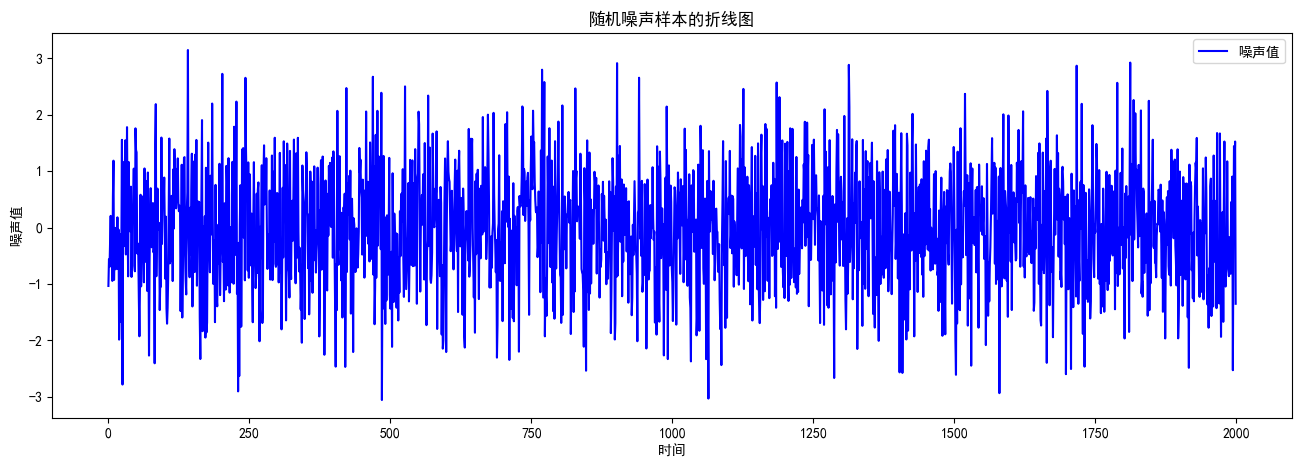

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore')
plt.rc('font', family='SimHei')
plt.rc('axes', unicode_minus=False)

# 生成随机噪声样本
noise_values = np.random.randn(2000)
plt.figure(figsize=(16, 5))
plt.plot(noise_values, color='blue', label='噪声值')
plt.title('随机噪声样本的折线图')
plt.xlabel('时间')
plt.ylabel('噪声值')
plt.legend()
plt.show()

由上图可知，白噪声数据值始终在0附近随机波动，而且波动的范围有界。

##### 4.1.2.2 自相关图检验

平稳序列具有短期相关性，这个性质表明对平稳序列而言通常只有近期的序列值对现时值的影响比较明显，间隔越远的过去值对现时值的影响越小。随着延迟期数k的增加，平稳序列的自相关系数$ρ_k$ （延迟$k$期）会比较快地衰减并趋向于零，并在零附近随机波动，而非平稳序列的自相关系数衰减的速度比较慢，这就是利用自相关图进行平稳性检验的标准。

**自相关和偏自相关**

因为时间序列这种数据的特点是一维（只有日期和对应的数据）。
统计中的相关性说的是两个变量间的相关程度，时间序列数据没有第二个变量来比较相关，所以形成了自相关函数、偏自相关函数和自协方差，也就是自己和自己的滞后期的数据进行比较。
- ACF(自相关函数)，ACF描述了该序列的当前值与其过去的值之间的相关程度。
- PACF(偏自相关函数)，PACF是残差（在去除了之前的滞后已经解释的影响之后仍然存在）与下一个滞后值的相关性。

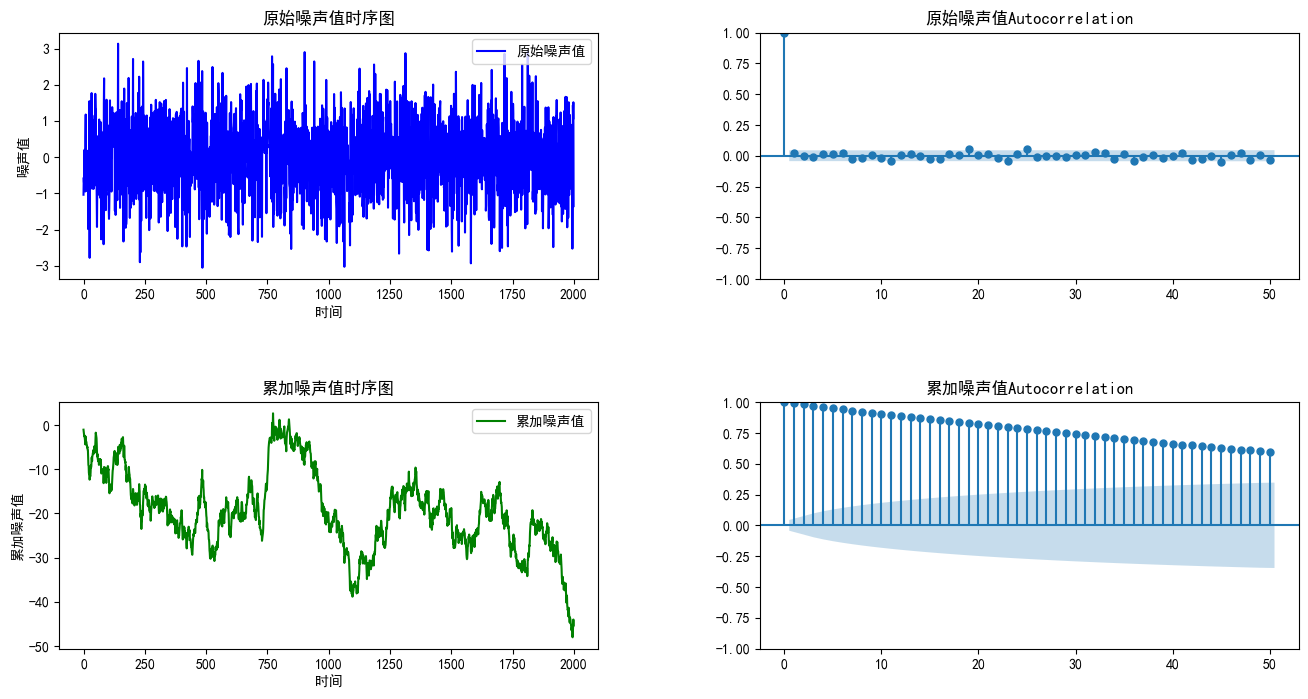

In [2]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, axes = plt.subplots(2, 2, figsize=(16, 8))

# 绘制原始噪声值时序图
axes[0, 0].plot(noise_values, color='blue', label='原始噪声值')
axes[0, 0].set_title('原始噪声值时序图')
axes[0, 0].set_xlabel('时间')
axes[0, 0].set_ylabel('噪声值')
axes[0, 0].legend()

# 绘制原始噪声值的自相关图
plot_acf(noise_values, ax=axes[0, 1], title='原始噪声值Autocorrelation', lags=50)

# 绘制噪声值累加后的时序图
cumsum_noise_values = np.cumsum(noise_values)
axes[1, 0].plot(cumsum_noise_values, color='green', label='累加噪声值')
axes[1, 0].set_title('累加噪声值时序图')
axes[1, 0].set_xlabel('时间')
axes[1, 0].set_ylabel('累加噪声值')
axes[1, 0].legend()

# 绘制累加噪声值的自相关图
plot_acf(cumsum_noise_values, ax=axes[1, 1], title='累加噪声值Autocorrelation', lags=50)
plt.subplots_adjust(hspace=0.5, wspace=0.3)
plt.show()

白噪声的自相关系数很快就衰减到0附近，是明显的平稳序列。

白噪声的累加数据从时序图上看曲线无确定趋势，均值、方差波动较大，是明显非平稳序列。并且自相关图中自相关系数下降非常缓慢，故为非平稳序列。

##### 4.1.2.3 ADF 检验

ADF检验即单位根检验是指检验序列中是否存在单位根，如果序列平稳，就不存在单位根；否则，就会存在单位根。
- H0原假设：序列有单位根
- 备择假设：序列没有单位根

In [4]:
from statsmodels.tsa.stattools import adfuller
from tqdm import tqdm
from IPython.display import display  # 如果是在jupyter中使用

# 在文件开头添加pandas显示配置（放在pd导入之后）
pd.set_option('display.float_format', '{:.4f}'.format)  # 固定4位小数
pd.set_option('display.unicode.ambiguous_as_wide', True)  # 对齐中文字符
pd.set_option('display.unicode.east_asian_width', True)

# 假设noise_values是一个预先定义好的数组
# 这里我们创建一个随机的白噪声数组作为示例
noise_values = np.random.randn(1000)

# 重复检验10次
num_iterations = 10
p_values = []

for _ in tqdm(range(num_iterations)):
    # 对于白噪声和其累加数据进行单位根检验，检验数据的平稳性
    p1 = adfuller(noise_values)[1]
    p2 = adfuller(np.cumsum(noise_values))[1]
    p_values.append((p1, p2))

# 创建 DataFrame，然后输出所有检验的p值
df_p_values = pd.DataFrame(p_values, columns=['白噪声数据p值', '白噪声累加数据p值']).T

# 打印整个 DataFrame，使用更美观的打印方式
print("\n整理后的p值表格：")
display(df_p_values.style.set_properties(**{'text-align': 'center'}))


100%|██████████| 10/10 [00:01<00:00,  9.88it/s]


整理后的p值表格：


,0,1,2,3,4,5,6,7,8,9
白噪声数据p值,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
白噪声累加数据p值,0.688233,0.688233,0.688233,0.688233,0.688233,0.688233,0.688233,0.688233,0.688233,0.688233


在显著性水平为95%的情况下
- 白噪声数据ADF检验p值小于0.05，拒绝原假设，即数据平稳。
- 白噪声累加数据ADF检验p值大于0.05，不拒绝原假设，即数据非平稳。

##### 4.1.2.4 白噪声检验

白噪声检验也称为纯随机性检验， 当数据是纯随机数据时，再对数据进行分析就没有了分析价值，所以要进行白噪声检验，LB检验可以确定数据是否为白噪声。
- 原假设HO：延迟期数小于或等于m期的序列之间相互独立(序列是白噪声)
- 备择假设：延迟期数小于或等于m期的序列之间有相关性(序列不是白噪声)

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# 假设 noise_values 已经定义
p1 = acorr_ljungbox(noise_values, lags=1)
p2 = acorr_ljungbox(np.cumsum(noise_values), lags=1)
print(p1, p2)

   lb_stat  lb_pvalue
1   0.2337     0.6288    lb_stat  lb_pvalue
1 991.1089     0.0000


在显著性水平为95%的情况下

- 白噪声数据白噪声检验p值大于0.05，不拒绝原假设，即数据是白噪声。
- 白噪声累加数据白噪声检验p值小于0.05，拒绝原假设，即数据不是白噪声。

### 4.2 ARMA 模型

ARMA模型为三种类型
- （1）AR(Auto Regressive)，即自回归序列模型
- （2）MA(Moving Average)，即移动平均序列模型
- （3）ARMA(Auto Regressive Moving Average)，即自回归移动平均模型

**例2**.下表为某市2010-2014年的PM2.5数据，试用部分数据建立平稳时间序列模型AR(p)、MA(q)、ARMA(p,q)，确定模型参数并预测剩下部分数据的PM2.5值，评估三个模型的预测效果。

> *原稿配图未随 notebook 保存，此处暂缺。*

#### 4.2.1 数据导入

首先导入数据。


In [8]:
df = pd.read_csv('../data/PM_data.csv')
df.T

,0,1,2,3,4,5,6,7,8,9,...,1816,1817,1818,1819,1820,1821,1822,1823,1824,1825
date,2010-1-1,2010-1-2,2010-1-3,2010-1-4,2010-1-5,2010-1-6,2010-1-7,2010-1-8,2010-1-9,2010-1-10,...,2014-12-22,2014-12-23,2014-12-24,2014-12-25,2014-12-26,2014-12-27,2014-12-28,2014-12-29,2014-12-30,2014-12-31
pm2.5,3096,3503,1892,752,1019,1354,1656,4229,2124,1374,...,2286,2445,339,648,4086,5728,4737,3816,1106,241


#### 4.2.2 划分数据集

本实验对数据划分原则为：“某一时刻”之前的数据作为训练集，之后的数据作为测试集，这里我们选择数据集前1800个数据作为训练集，剩下的数据作为测试集。

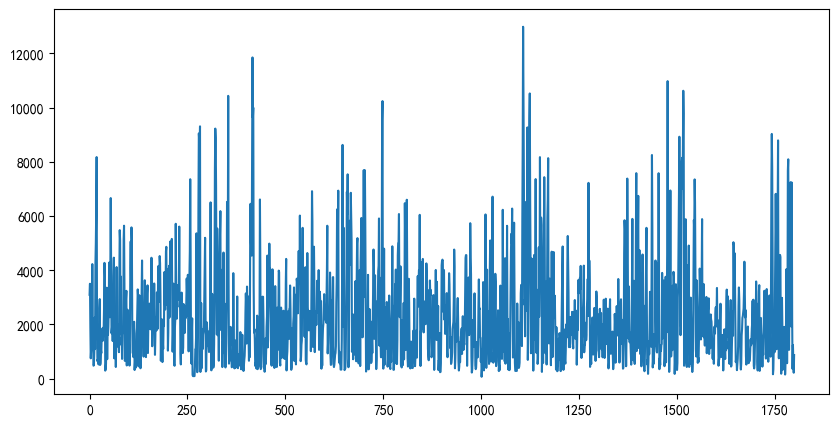

In [9]:
# 数据集划分前1800个数据作为训练数据
train = df.iloc[:1800]
train_d = train['date']
train_y = train['pm2.5']
# 数据集划分剩下的数据作为测试数据
test = df.iloc[1800:]
test_d = test['date']
test_y = test['pm2.5']

# 绘图
plt.figure(figsize=(10,5))
# 查看训练数据的时序图
plt.plot(train_y)
plt.show()

#### 4.2.3 序列检验

In [10]:
p1 = acorr_ljungbox(train_y, lags=range(1, 10))
print('时序数据白噪声检验的p值为:', p1)

p2 = adfuller(train_y)[1]
print('时序数据单位根检验的p值为:', p2)


时序数据白噪声检验的p值为:    lb_stat  lb_pvalue
1 586.4327     0.0000
2 670.3930     0.0000
3 679.7762     0.0000
4 680.3000     0.0000
5 681.7660     0.0000
6 683.0859     0.0000
7 683.8127     0.0000
8 685.5072     0.0000
9 687.5609     0.0000
时序数据单位根检验的p值为: 9.67121171136035e-29


在显著性水平为95%的情况下

- 时序数据白噪声检验p值小于0.05，拒绝原假设，即数据不是白噪声。
- 时序数据ADF检验p值小于0.05，拒绝原假设，即数据平稳。

#### 4.2.4 参数估计

ARMA(p,q)模型，主要包括两个参数：
- p：自回归模型阶数
- q：移动平均模型阶数

模型定阶就是指选择适合的ARMA(p,q)模型的参数p和q，主要有两种方法：
1. 利用自相关系数和偏自相关系数
2. 利用最优信息准则

##### 4.2.4.1 利用自相关系数和偏自相关系数

|模型   |AR(p)   |MA(q)  |ARMA(p,q)   |
|-------- |-------- |-------- |-------- |
| ACF自相关系数   | 拖尾  |  q阶截尾   | p阶拖尾   |
| PACF偏自相关系数   | p阶截尾  |  拖尾   |  q阶拖尾   |

- 截尾：在最初d阶时明显大于2倍的标准差范围，而后面集合95.5%以上都落在2倍标准差范围之内，并且由非零值衰减为小值波动的过程非常突然，可认为d阶-截尾。
- 拖尾：有超过5%的值落入2倍标准差范围之外，或显著衰减为小值波动的过程比较缓慢，则拖尾。

<Figure size 900x500 with 0 Axes>

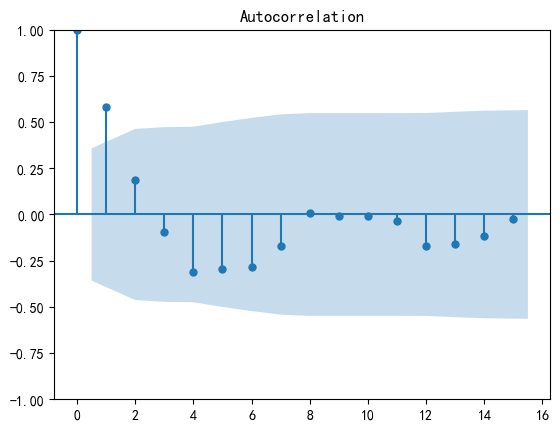

In [11]:
plt.figure(figsize=[9,5])
# 第一个子图绘制自相关图像
plot_acf(train_y[:30])
plt.show()

<Figure size 900x500 with 0 Axes>

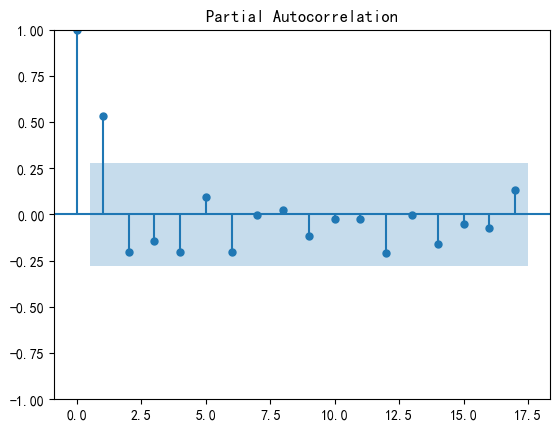

In [12]:
plt.figure(figsize=[9,5])
# 第一个子图绘制自相关图像
plot_pacf(train_y[:50])
plt.show()

##### 4.2.4.2 利用最优信息准则

根据最简约原则，常见的做法是实现选择多组(p, q)组合，通过参数估计建立多个ARMA模型，同时经过模型检验确定机组都能通过检验的(p, q)组合，然后根据AIC、BIC、HQIC等信息准则确定一组最好的(p, q)值。信息准则值越小，模型越好。

本次实验我们使用AIC准则确定模型阶数。

AIC (Akaike information criterion,赤池信息量) 可以表示为：

$$AIC=2k-2ln(L)$$

其中：k是参数的数量，L是似然函数。假设条件是模型的误差服从独立正态分布。

In [13]:
import pmdarima as pm

# 使用pmdarima库的auto_arima函数，同时限制p和q的最大值，设置信息准则为aic
model = pm.auto_arima(train_y, max_p=6, max_q=6, information_criterion='aic', trace=True, error_action='ignore', suppress_warnings=True)

# 获取最佳p和q值
p, q = model.order[0], model.order[2]


print(f'ARMA模型参数最佳取值: (p={p}, q={q})')


Performing stepwise search to minimize aic
 ARIMA(2,0,2)(0,0,0)[0] intercept   : AIC=31439.378, Time=0.36 sec
 ARIMA(0,0,0)(0,0,0)[0] intercept   : AIC=32190.161, Time=0.04 sec
 ARIMA(1,0,0)(0,0,0)[0] intercept   : AIC=31484.015, Time=0.07 sec
 ARIMA(0,0,1)(0,0,0)[0] intercept   : AIC=31528.500, Time=0.37 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=33920.383, Time=0.02 sec
 ARIMA(1,0,2)(0,0,0)[0] intercept   : AIC=31439.865, Time=0.22 sec
 ARIMA(2,0,1)(0,0,0)[0] intercept   : AIC=31440.556, Time=0.45 sec
 ARIMA(3,0,2)(0,0,0)[0] intercept   : AIC=31440.596, Time=0.70 sec
 ARIMA(2,0,3)(0,0,0)[0] intercept   : AIC=31440.870, Time=0.55 sec
 ARIMA(1,0,1)(0,0,0)[0] intercept   : AIC=31444.386, Time=0.21 sec
 ARIMA(1,0,3)(0,0,0)[0] intercept   : AIC=31440.942, Time=0.30 sec
 ARIMA(3,0,1)(0,0,0)[0] intercept   : AIC=31440.196, Time=0.50 sec
 ARIMA(3,0,3)(0,0,0)[0] intercept   : AIC=inf, Time=2.36 sec
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=inf, Time=1.23 sec

Best model:  ARIMA(2,0,2)(0,0,

所以创建三个模型：AR(5)、MA(2)、ARMA(5,2)查看模型AIC和BIC的值。

#### 4.2.5 模型创建

In [14]:
from statsmodels.tsa.arima.model import ARIMA

def fit_arma_model(train_y, order):
    try:
        model = ARIMA(train_y, order=order).fit()
        return model.aic, model.bic
    except Exception as e:
        print(f"模型拟合失败，错误信息为：{e}")
        return None, None

orders = {'AR(5)': (5, 0, 0), 'MA(2)': (0, 0, 2), 'ARMA(5,2)': (5, 0, 2)}
results = {}

for name, order in orders.items():
    aic, bic = fit_arma_model(train_y, order)
    if aic is not None and bic is not None:
        results[name] = (aic, bic)

# 打印结果
for name, (aic, bic) in results.items():
    print(f'{name}模型AIC的值为: {aic}')
    print(f'{name}模型BIC的值为: {bic}')


AR(5)模型AIC的值为: 31437.93241886596
AR(5)模型BIC的值为: 31476.40121247315
MA(2)模型AIC的值为: 31450.91306175516
MA(2)模型BIC的值为: 31472.895229530695
ARMA(5,2)模型AIC的值为: 31432.37872506321
ARMA(5,2)模型BIC的值为: 31481.838602558168


d:\CodingRation\10-Python数学建模\Python_mathematical_modeling\.venv\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


#### 4.2.6 残差检验

为了确保确定的阶数合适，还需要进行残差检验。残差即原始信号减掉模型拟合出的信号后的残余信号。如果残差是随机正态分布的、不自相关的，这说明残差是一段白噪声信号，也就说明有用的信号已经都被提取到ARMA模型中了。

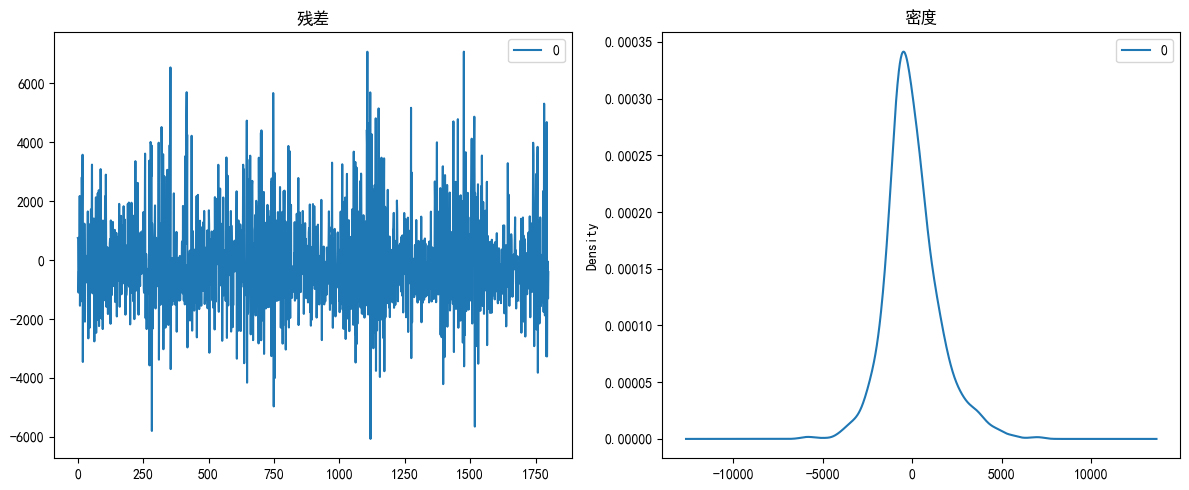

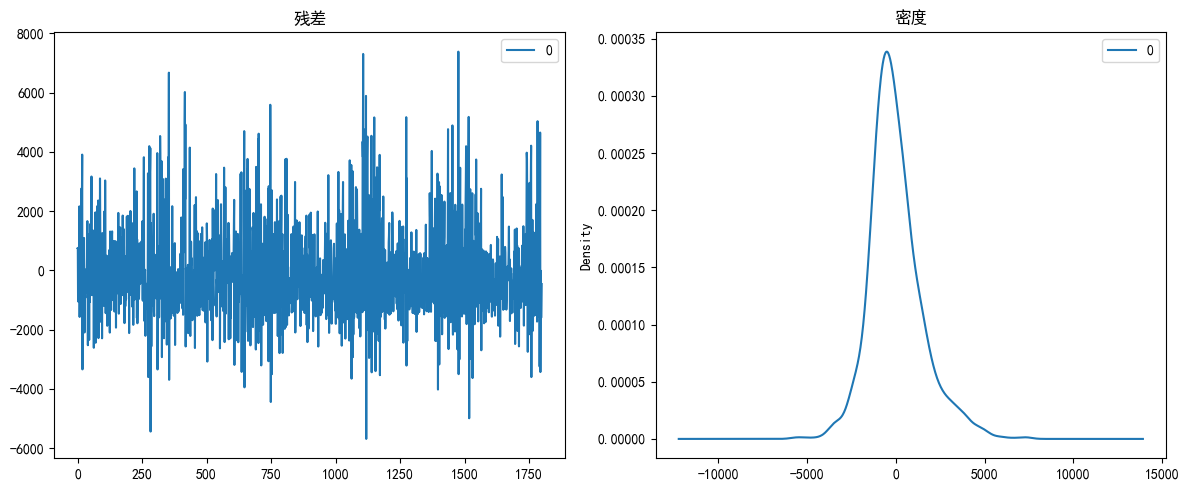

d:\CodingRation\10-Python数学建模\Python_mathematical_modeling\.venv\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


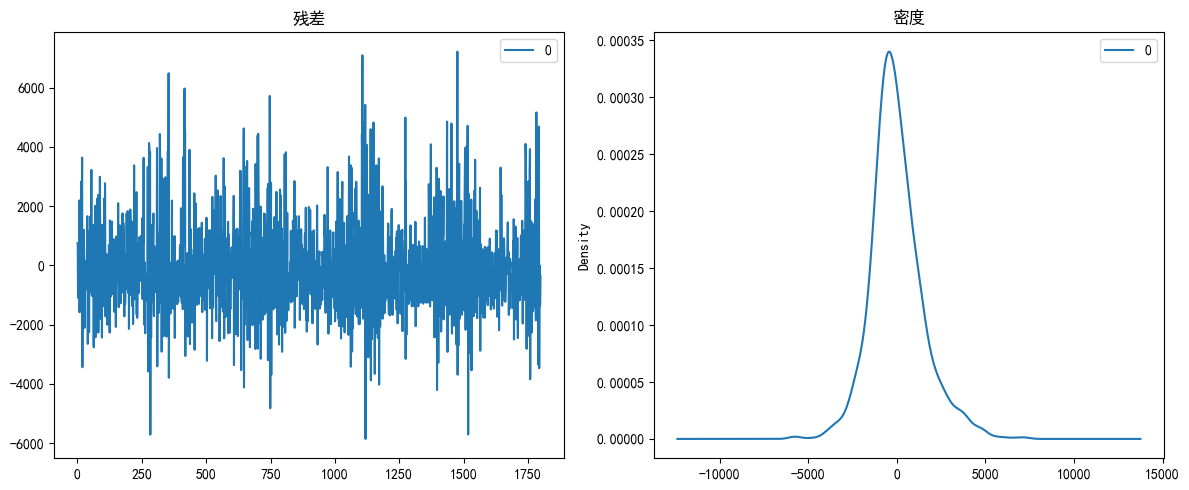

In [15]:
from statsmodels.tsa.arima.model import ARIMA
import pandas as pd
import matplotlib.pyplot as plt

def fit_arma_model(train_y, order):
    try:
        model = ARIMA(train_y, order=order).fit()
        return model
    except Exception as e:
        print(f"模型拟合失败，错误信息为：{e}")
        return None

orders = {'AR(5)': (5, 0, 0), 'MA(2)': (0, 0, 2), 'ARMA(5,2)': (5, 0, 2)}
results = {}

for name, order in orders.items():
    model = fit_arma_model(train_y, order)
    if model is not None:
        results[name] = (model.aic, model.bic)
        arma = model  # 假设你使用的是最后一个成功的模型进行残差分析
        # 进行残差分析
        residuals = pd.DataFrame(arma.resid)
        fig, ax = plt.subplots(1, 2, figsize=(12, 5))
        residuals.plot(title="残差", ax=ax[0])
        residuals.plot(kind='kde', title='密度', ax=ax[1])
        plt.tight_layout()
        plt.show()


上图为残差检验的结果图。理想的残差要接近正态分布。

#### 4.2.7 模型预测

根据AIC的值，选择ARMA(5,2)模型对测试数据进行预测。

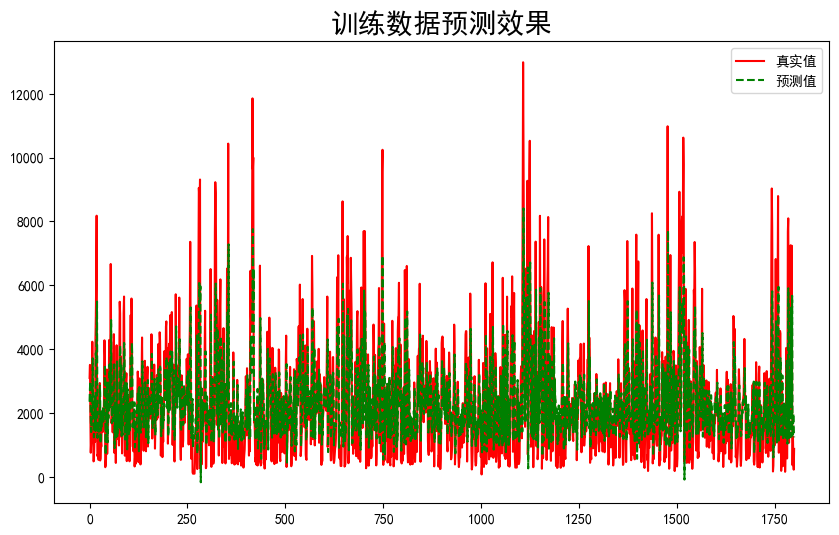

In [16]:
# fittedvalues对训练数据预测
y_pre = arma.fittedvalues
# 绘制真实值和预测值的曲线
plt.figure(figsize=(10,6))
plt.plot(train_y,'r-',label='真实值')
plt.plot(y_pre,'g--',label='预测值')
plt.title('训练数据预测效果',fontsize=20)
plt.legend()
plt.show()

d:\CodingRation\10-Python数学建模\Python_mathematical_modeling\.venv\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


AR(5)模型AIC的值为: 31437.93241886596
AR(5)模型BIC的值为: 31476.40121247315
MA(2)模型AIC的值为: 31450.91306175516
MA(2)模型BIC的值为: 31472.895229530695
ARMA(5,2)模型AIC的值为: 31432.37872506321
ARMA(5,2)模型BIC的值为: 31481.838602558168


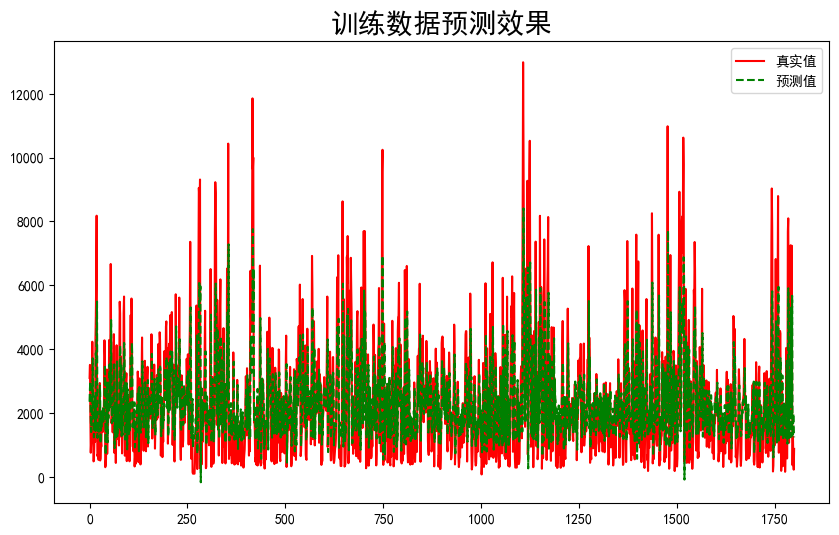

In [17]:
from statsmodels.tsa.arima.model import ARIMA
import pandas as pd
import matplotlib.pyplot as plt

def fit_arma_model(train_y, order):
    try:
        model = ARIMA(train_y, order=order).fit()
        return model
    except Exception as e:
        print(f"模型拟合失败，错误信息为：{e}")
        return None

# 示例数据集
# 确保 train_y 已经定义并且包含适当的数据
# train_y = pd.Series([...])

orders = {'AR(5)': (5, 0, 0), 'MA(2)': (0, 0, 2), 'ARMA(5,2)': (5, 0, 2)}
results = {}

for name, order in orders.items():
    model = fit_arma_model(train_y, order)
    if model is not None:
        results[name] = (model.aic, model.bic)
        arma = model  # 假设你使用的是最后一个成功的模型进行预测

# 打印结果
for name, (aic, bic) in results.items():
    print(f'{name}模型AIC的值为: {aic}')
    print(f'{name}模型BIC的值为: {bic}')

# 确保 arma 模型对象已经成功拟合
if arma is not None:
    # 获取拟合值
    y_pre = arma.fittedvalues
    
    # 检查 train_y 和 y_pre 的形状是否一致
    if train_y.shape == y_pre.shape:
        # 绘制真实值和预测值的曲线
        plt.figure(figsize=(10, 6))
        plt.plot(train_y, 'r-', label='真实值')
        plt.plot(y_pre, 'g--', label='预测值')
        plt.title('训练数据预测效果', fontsize=20)
        plt.legend()
        plt.show()
    else:
        print(f"train_y 和 y_pre 的形状不一致: {train_y.shape} != {y_pre.shape}")
else:
    print("未成功拟合任何 ARMA 模型")


ARMA模型预测的三个方法fittedvalues、forecast和predict的：
- fittedvalues: fittedvalues方法用于获取ARMA模型对原始数据进行拟合后的值，即模型对历史数据的预测值。这个方法的输出结果是一个Series对象，其中包含了每个时间点上模型预测的值。
- forecast: forecast方法用于对未来数据进行预测，即预测下一步或多步的值。这个方法的输出结果是一个Series对象，其中包含了每个时间点上模型预测的值。
- predict: predict方法是forecast方法的一个更通用的版本。它允许在任意时间点上进行预测，并可以指定预测的步数。predict方法的输出结果是一个Series对象，其中包含了每个时间点上模型预测的值。

三个方法的区别主要在于它们预测的时间范围和精度。fittedvalues方法只预测历史数据的值，而forecast和predict方法可以预测未来数据的值。在预测精度方面，fittedvalues方法的精度最高，因为它是对历史数据进行拟合的结果，而forecast和predict方法的预测精度则取决于模型的准确性和预测时间的远近。

**ARMA适合短期预测，因为其基本假设是时间序列是平稳的，无法处理复杂的非线性关系，对异常值和噪声敏感，而且当预测的时间跨度较长时，时间序列可能存在趋势或季节性变化，需要使用更复杂的模型**。


## 5. 小结

本次实验介绍了序列平稳性检验的常用方法和ARMA模型的创建、参数估计、残差检验和预测。并通过实际例子基于Python实现ARMA模型预测。

通过本次实验需要掌握以下内容：
- 掌握序列平稳性检验
- 掌握ARMA模型的检验、参数估计和预测
